In [ ]:
%pip install numpy matplotlib opencv-python

In [ ]:
%pip install open3d

---

## Q1(a) — 2D transformations: translation, rotation, scaling, and shearing



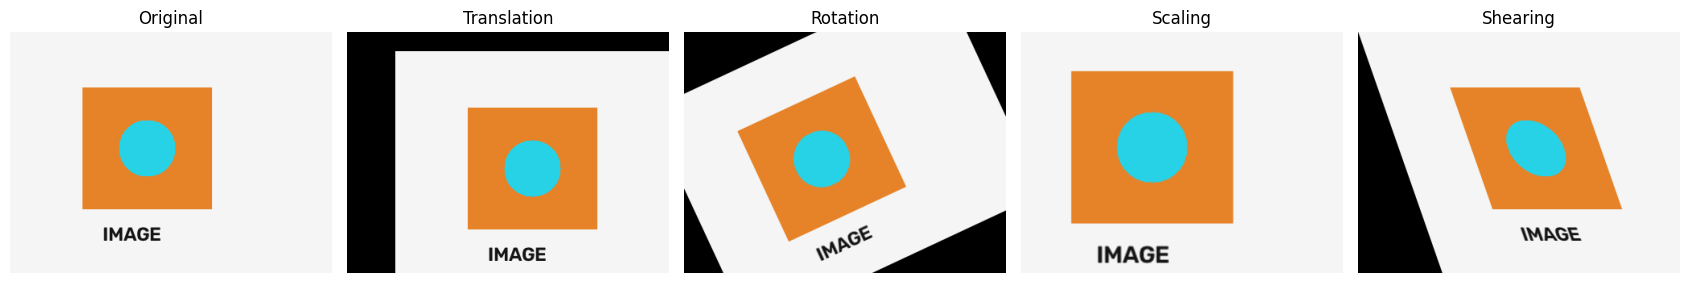

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

# Make a simple example image with a colored rectangle and a circle
image = np.ones((300, 400, 3), dtype=np.uint8) * 245
cv2.rectangle(image, (90, 70), (250, 220), (40, 130, 230), -1)
cv2.circle(image, (170, 145), 35, (230, 210, 40), -1)
cv2.putText(image, "IMAGE", (115, 260), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (20, 20, 20), 2)

h, w = image.shape[:2]

# Translation: move right by 60 px and down by 25 px
T = np.float32([[1, 0, 60], [0, 1, 25]])
translated = cv2.warpAffine(image, T, (w, h))

# Rotation: rotate 25 degrees around the image center
R = cv2.getRotationMatrix2D((w / 2, h / 2), 25, 1.0)
rotated = cv2.warpAffine(image, R, (w, h))

# Scaling: enlarge by 1.25 around the center
S = cv2.getRotationMatrix2D((w / 2, h / 2), 0, 1.25)
scaled = cv2.warpAffine(image, S, (w, h))

# Shearing: x' = x + 0.35y
H_shear = np.float32([[1, 0.35, 0], [0, 1, 0]])
sheared = cv2.warpAffine(image, H_shear, (w, h))

fig, axes = plt.subplots(1, 5, figsize=(17, 4))
for ax, im, title in zip(
    axes,
    [image, translated, rotated, scaled, sheared],
    ["Original", "Translation", "Rotation", "Scaling", "Shearing"]
):
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Q1(b) — 3D transformation along the x, y, and z axes


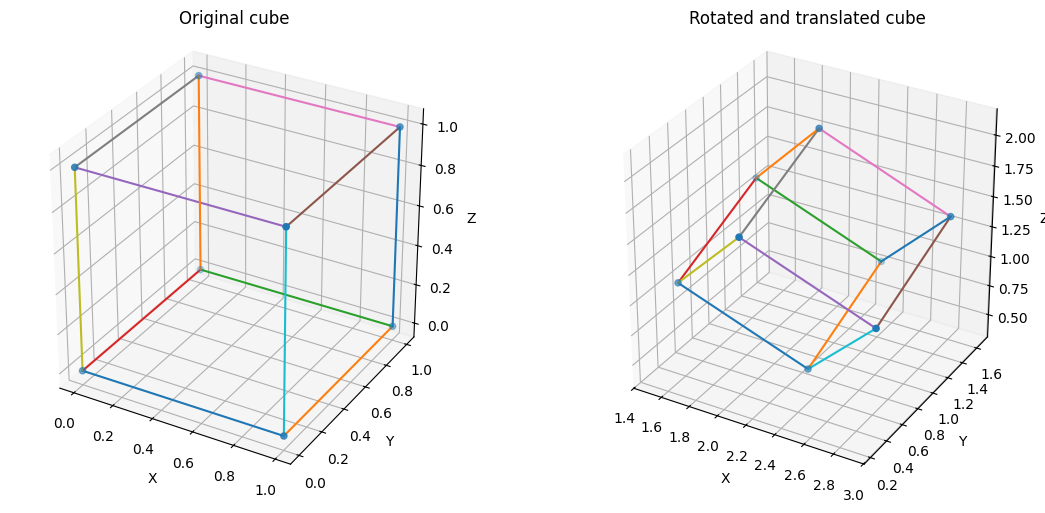

In [2]:
from mpl_toolkits.mplot3d import Axes3D

# Eight vertices of a unit cube
points = np.array([
    [0, 0, 0], [1, 0, 0], [1, 1, 0], [0, 1, 0],
    [0, 0, 1], [1, 0, 1], [1, 1, 1], [0, 1, 1]
], dtype=float)

theta_x = np.radians(25)
theta_y = np.radians(35)
theta_z = np.radians(15)

Rx = np.array([
    [1, 0, 0],
    [0, np.cos(theta_x), -np.sin(theta_x)],
    [0, np.sin(theta_x), np.cos(theta_x)]
])
Ry = np.array([
    [np.cos(theta_y), 0, np.sin(theta_y)],
    [0, 1, 0],
    [-np.sin(theta_y), 0, np.cos(theta_y)]
])
Rz = np.array([
    [np.cos(theta_z), -np.sin(theta_z), 0],
    [np.sin(theta_z), np.cos(theta_z), 0],
    [0, 0, 1]
])

rotated_points = points @ (Rz @ Ry @ Rx).T
transformed_points = rotated_points + np.array([1.5, 0.5, 1.0])

edges = [
    (0,1),(1,2),(2,3),(3,0),
    (4,5),(5,6),(6,7),(7,4),
    (0,4),(1,5),(2,6),(3,7)
]

fig = plt.figure(figsize=(12, 5))
for subplot, pts, title in [(1, points, "Original cube"), (2, transformed_points, "Rotated and translated cube")]:
    ax = fig.add_subplot(1, 2, subplot, projection="3d")
    for i, j in edges:
        ax.plot(*zip(pts[i], pts[j]))
    ax.scatter(pts[:, 0], pts[:, 1], pts[:, 2])
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")
    ax.set_title(title)
    ax.set_box_aspect([1, 1, 1])
plt.tight_layout()
plt.show()

**Observation:** 3D rotation changes the orientation of the object around an axis. Translation moves it along x, y, or z without changing its shape.

## Q1(c) — Homogeneous coordinates



In [3]:
point = np.array([4,  3, 1])  # homogeneous point (x, y, 1)

translation_matrix = np.array([
    [1, 0, 5],
    [0, 1, 2],
    [0, 0, 1]
])

translated_point = translation_matrix @ point
print("Original homogeneous point:", point)
print("After translation:", translated_point)
print("Cartesian coordinates after translation:", translated_point[:2] / translated_point[2])

Original homogeneous point: [4 3 1]
After translation: [9 5 1]
Cartesian coordinates after translation: [9. 5.]


## Q1(d) — Affine transformation



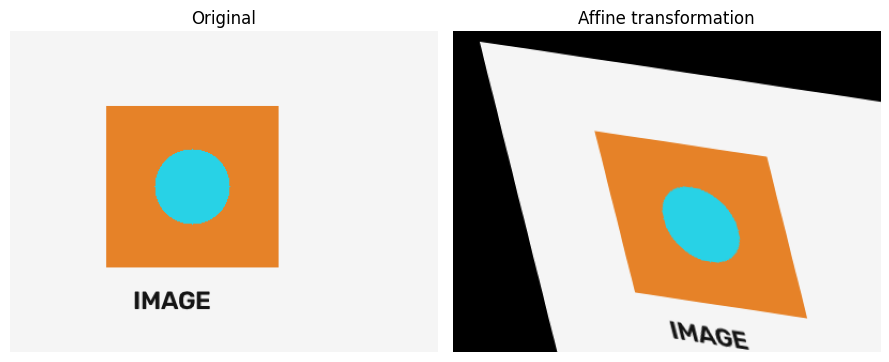

In [4]:
# Apply a single affine transformation to the example image
affine_matrix = np.float32([
    [1.0, 0.25, 25],
    [0.15, 1.0, 10]
])
affine_image = cv2.warpAffine(image, affine_matrix, (w, h))

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
axes[0].set_title("Original")
axes[1].imshow(cv2.cvtColor(affine_image, cv2.COLOR_BGR2RGB))
axes[1].set_title("Affine transformation")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

**Result:** straight edges remain straight after the affine transformation. Parallel edges remain parallel. The shape may be slanted or resized, but the transformation does not introduce perspective convergence.

## Q1(e) — Projective transformation (homography)



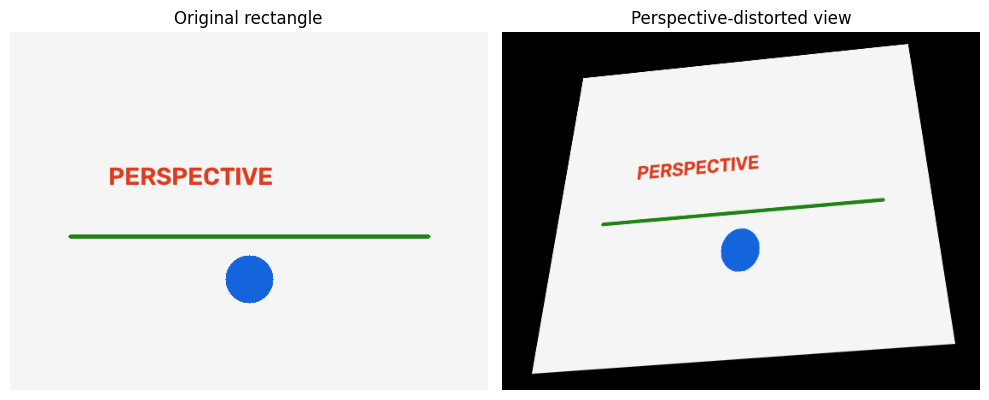

In [5]:
# Create a perspective-distorted quadrilateral as an example "tilted" surface
canvas = np.zeros((420, 560, 3), dtype=np.uint8)
cv2.rectangle(canvas, (0, 0), (559, 419), (245, 245, 245), -1)
cv2.putText(canvas, "PERSPECTIVE", (115, 180), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (30, 60, 220), 3)
cv2.line(canvas, (70, 240), (490, 240), (20, 130, 30), 4)
cv2.circle(canvas, (280, 290), 28, (220, 100, 20), -1)

src = np.float32([[0, 0], [559, 0], [559, 419], [0, 419]])
dst = np.float32([[95, 55], [475, 15], [530, 365], [35, 400]])

perspective_matrix = cv2.getPerspectiveTransform(src, dst)
tilted = cv2.warpPerspective(canvas, perspective_matrix, (560, 420))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
axes[0].set_title("Original rectangle")
axes[1].imshow(cv2.cvtColor(tilted, cv2.COLOR_BGR2RGB))
axes[1].set_title("Perspective-distorted view")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

---

## Q2 — Perspective correction (unwarping)


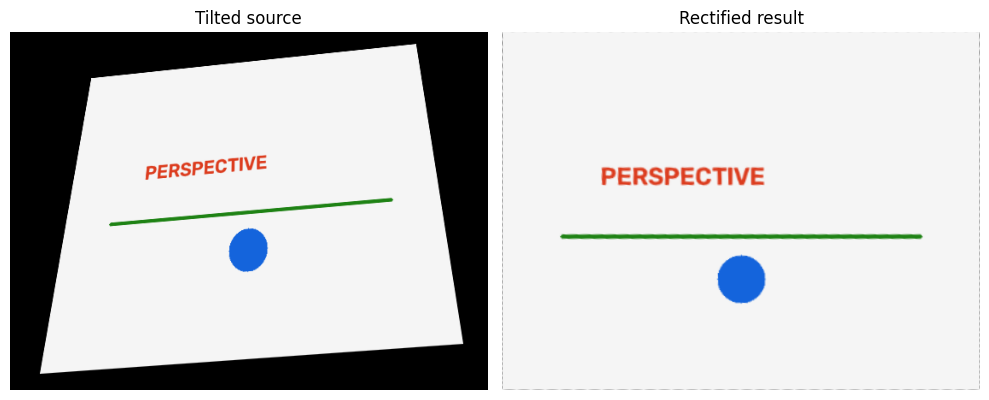

In [6]:
# Use the tilted example created above
source_image = tilted

# Approximate corners of the tilted rectangle in the example image
source_points = np.float32([
    [95, 55], [475, 15], [530, 365], [35, 400]
])

output_width, output_height = 560, 420
destination_points = np.float32([
    [0, 0],
    [output_width - 1, 0],
    [output_width - 1, output_height - 1],
    [0, output_height - 1]
])

inverse_homography = cv2.getPerspectiveTransform(source_points, destination_points)
unwarped = cv2.warpPerspective(source_image, inverse_homography, (output_width, output_height))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(cv2.cvtColor(source_image, cv2.COLOR_BGR2RGB))
axes[0].set_title("Tilted source")
axes[1].imshow(cv2.cvtColor(unwarped, cv2.COLOR_BGR2RGB))
axes[1].set_title("Rectified result")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

**Key point:** `getPerspectiveTransform(source_points, destination_points)` computes the mapping from the four selected source corners to the destination rectangle. `warpPerspective` applies that mapping. For a different real-world photo, the corner coordinates must be measured for that photo.

---

## Q3 — Undistort a live camera feed



In [7]:
# Run this cell only after preparing camera_calibration.npz
# The file must contain: camera_matrix and dist_coeffs

import os
import cv2
import numpy as np

calibration_file = "camera_calibration.npz"

if not os.path.exists(calibration_file):
    print("Calibration file not found:", calibration_file)
    print("Calibrate your camera first, then save camera_matrix and dist_coeffs in this file.")
else:
    calibration = np.load(calibration_file)
    camera_matrix = calibration["camera_matrix"]
    dist_coeffs = calibration["dist_coeffs"]

    cap = cv2.VideoCapture(0)
    if not cap.isOpened():
        print("Could not open webcam. Check camera permissions or camera index.")
    else:
        print("Press q in the camera window to quit.")
        while True:
            ret, frame = cap.read()
            if not ret:
                print("Could not read a frame from the camera.")
                break

            undistorted = cv2.undistort(frame, camera_matrix, dist_coeffs)
            comparison = np.hstack((frame, undistorted))
            cv2.imshow("Original (left) | Undistorted (right)", comparison)

            if cv2.waitKey(1) & 0xFF == ord("q"):
                break

        cap.release()
        cv2.destroyAllWindows()

Calibration file not found: camera_calibration.npz
Calibrate your camera first, then save camera_matrix and dist_coeffs in this file.


---

## Q4 — Build a 3D model from images using COLMAP



In [8]:
# Terminal commands — run in a system terminal, not as Python code.
#
# 1. Extract image features
# colmap feature_extractor \
#   --database_path database.db \
#   --image_path images
#
# 2. Match features across images
# colmap exhaustive_matcher \
#   --database_path database.db
#
# 3. Estimate camera poses and create a sparse reconstruction
# mkdir sparse
# colmap mapper \
#   --database_path database.db \
#   --image_path images \
#   --output_path sparse
#
# 4. Undistort images and prepare the dense workspace
# mkdir dense
# colmap image_undistorter \
#   --image_path images \
#   --input_path sparse/0 \
#   --output_path dense \
#   --output_type COLMAP
#
# 5. Create a dense point cloud
# colmap patch_match_stereo --workspace_path dense
# colmap stereo_fusion \
#   --workspace_path dense \
#   --output_path dense/fused.ply

### C. Visualize the reconstructed point cloud



In [9]:
import os

point_cloud_path = "dense/fused.ply"

if not os.path.exists(point_cloud_path):
    print("Point cloud not found:", point_cloud_path)
    print("Run the COLMAP dense reconstruction steps first.")
else:
    try:
        import open3d as o3d
        cloud = o3d.io.read_point_cloud(point_cloud_path)
        print(cloud)
        o3d.visualization.draw_geometries([cloud], window_name="COLMAP Dense Point Cloud")
    except ImportError:
        print("Install Open3D first using: %pip install open3d")

Point cloud not found: dense/fused.ply
Run the COLMAP dense reconstruction steps first.


### D. Create a mesh from the point cloud (optional reconstruction step)


In [10]:
if os.path.exists(point_cloud_path):
    try:
        import open3d as o3d
        cloud = o3d.io.read_point_cloud(point_cloud_path)
        cloud.estimate_normals()
        distances = cloud.compute_nearest_neighbor_distance()
        if len(distances) > 0:
            radius = float(np.mean(distances) * 2.5)
            radii = [radius, radius * 2]
            mesh = o3d.geometry.TriangleMesh.create_from_point_cloud_ball_pivoting(
                cloud,
                o3d.utility.DoubleVector(radii)
            )
            mesh.compute_vertex_normals()
            o3d.io.write_triangle_mesh("dense/reconstructed_mesh.ply", mesh)
            print("Saved mesh to dense/reconstructed_mesh.ply")
            o3d.visualization.draw_geometries([mesh], window_name="Reconstructed Mesh")
        else:
            print("Point cloud has no points; cannot build a mesh.")
    except ImportError:
        print("Install Open3D first using: %pip install open3d")
else:
    print("Run dense reconstruction first so dense/fused.ply exists.")

Run dense reconstruction first so dense/fused.ply exists.
